# Tweezer Array Design Lab

Python companion to the AMO Toolkit page [Tweezer Array Design Lab](https://amotoolkit.com/pages/tweezer-designer.html). It reproduces the page's calculator with the same constants and formulas, so you can change anything, script a scan, or check a number in your own analysis.

[Open in Colab](https://colab.research.google.com/github/saumitraphatak/amo-career/blob/main/notebooks/tweezer-designer.ipynb) · needs only `numpy`, `scipy` and `matplotlib`.

## 1. Model
Two-level dipole potential and scattering rate including the counter-rotating term (Grimm, Weidemüller & Ovchinnikov 2000, Eqs. 10–11):

$U = -\frac{3\pi c^2}{2\omega_0^3}\left(\frac{\Gamma}{\omega_0-\omega}+\frac{\Gamma}{\omega_0+\omega}\right) I,\qquad
\Gamma_\mathrm{sc} = \frac{3\pi c^2}{2\hbar\omega_0^3}\left(\frac{\omega}{\omega_0}\right)^3\left(\frac{\Gamma}{\omega_0-\omega}+\frac{\Gamma}{\omega_0+\omega}\right)^2 I$

The waist is the Gaussian matched to a filled, diffraction-limited pupil, $w_0 = (\sqrt2/\pi)\,\lambda/\mathrm{NA} \approx 0.45\,\lambda/\mathrm{NA}$.

**Read with care:** one transition per species. For alkalis this ignores the D1 line and the fine-structure-resolved polarisability, so depths at wavelengths near the D lines are only indicative; use a multi-level polarisability for a real design.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

C, hbar, kB, amu = 299792458, 1.054571817e-34, 1.380649e-23, 1.66053906660e-27
SPECIES = {   # mass (u), transition λ (m), Γ/2π (Hz)
    "Rb87": (87, 780.24e-9, 6.065e6), "Cs133": (133, 852.347e-9, 5.234e6), "Li6": (6, 670.98e-9, 5.872e6),
    "Li7": (7, 670.96e-9, 5.872e6), "Na23": (23, 589.158e-9, 9.795e6), "K39": (39, 766.70e-9, 6.035e6),
    "Yb171": (171, 398.91e-9, 29.1e6), "Sr88": (88, 460.86e-9, 32.0e6),
}

def trap(species="Rb87", lam_nm=850, NA=0.55, P_mW=30):
    m_u, lam0, G_Hz = SPECIES[species]
    m, G = m_u * amu, 2 * np.pi * G_Hz
    w0_, w = 2 * np.pi * C / lam0, 2 * np.pi * C / (lam_nm * 1e-9)
    w0 = np.sqrt(2) / np.pi * lam_nm * 1e-9 / NA
    zR = np.pi * w0**2 / (lam_nm * 1e-9)
    I0 = 2 * P_mW * 1e-3 / (np.pi * w0**2)
    a = G / (w0_ - w) + G / (w0_ + w)
    U = -(3 * np.pi * C**2) / (2 * w0_**3) * a * I0
    Gsc = (3 * np.pi * C**2) / (2 * hbar * w0_**3) * (w / w0_) ** 3 * a**2 * I0
    wr = np.sqrt(4 * abs(U) / (m * w0**2)); wz = np.sqrt(2 * abs(U) / (m * zR**2))
    eta = 2 * np.pi / lam0 * np.sqrt(hbar / (2 * m * wr))
    return dict(w0_um=w0 * 1e6, zR_um=zR * 1e6, I0_1e10=I0 * 1e-10, U0_mK=abs(U) / kB * 1e3,
                f_r_kHz=wr / (2 * np.pi * 1e3), f_z_kHz=wz / (2 * np.pi * 1e3), eta=eta, Gsc=Gsc,
                valid=(w - w0_) < -3 * G)

r = trap()     # page defaults: Rb-87, 850 nm, NA 0.55, 30 mW per site
for k, v in r.items():
    print(f"{k:>8} = {v:.4g}" if not isinstance(v, (bool, np.bool_)) else f"{k:>8} = {v}")

   w0_um = 0.6957
   zR_um = 1.789
 I0_1e10 = 3.946
   U0_mK = 17.25
 f_r_kHz = 587.5
 f_z_kHz = 161.6
     eta = 0.08007
     Gsc = 350.4
   valid = True

## 2. Depth and scattering against wavelength
Same power and NA. Moving further from resonance costs depth (∝ 1/Δ) but cuts scattering faster (∝ 1/Δ²), so the photon-scattering heating per unit depth falls as you detune.

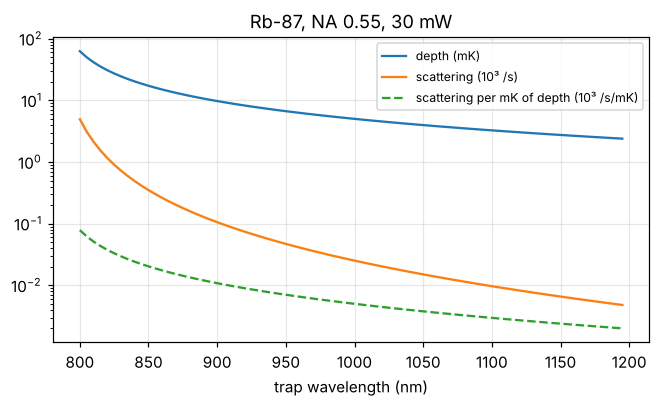

In [2]:
lams = np.arange(800, 1200, 5)
U = np.array([trap(lam_nm=l)["U0_mK"] for l in lams]); S = np.array([trap(lam_nm=l)["Gsc"] for l in lams])
fig, ax = plt.subplots()
ax.semilogy(lams, U, label="depth (mK)"); ax.semilogy(lams, S / 1e3, label="scattering (10³ /s)")
ax.semilogy(lams, S / U / 1e3, "--", label="scattering per mK of depth (10³ /s/mK)")
ax.set_xlabel("trap wavelength (nm)"); ax.legend(fontsize=8); ax.set_title("Rb-87, NA 0.55, 30 mW")

## 3. Scaling with NA
$w_0 \propto 1/\mathrm{NA}$, so at fixed power $U \propto \mathrm{NA}^2$, $\omega_r \propto \sqrt{U}/w_0 \propto \mathrm{NA}^2$ and $\omega_z \propto \sqrt{U}/z_R \propto \mathrm{NA}^3$. (This is problem 2 of week 8 in the course.)

In [3]:
base, low = trap(NA=0.55), trap(NA=0.55 * 0.7)
for k in ("U0_mK", "f_r_kHz", "f_z_kHz"):
    print(f"{k:>8}: ratio {low[k]/base[k]:.3f}  (prediction {0.7**{'U0_mK':2,'f_r_kHz':2,'f_z_kHz':3}[k]:.3f})")

   U0_mK: ratio 0.490  (prediction 0.490)
 f_r_kHz: ratio 0.490  (prediction 0.490)
 f_z_kHz: ratio 0.343  (prediction 0.343)

## 4. Array budget
Total power is N<sub>x</sub>·N<sub>y</sub>·P (before losses in the AOD or SLM, which are often 50% or more). The page flags spacing/waist ≥ 3 as negligible crosstalk.

In [4]:
nx, ny, d_um, P = 5, 5, 5.0, 30
print(f"sites {nx*ny}, total power {nx*ny*P} mW at the atoms, spacing/waist = {d_um/r['w0_um']:.1f}")

sites 25, total power 750 mW at the atoms, spacing/waist = 7.2

## 5. Check against the page

In [5]:
def check(ours, page, rel=0.006):
    """Compare our numbers with the values the web page shows at its default settings."""
    bad = []
    for k, shown in page.items():
        v = ours[k]
        ok = abs(v - shown) <= rel * abs(shown) + 1e-12 or abs(v - shown) <= 0.5 * 10 ** -DECIMALS.get(k, 99)
        print(f"{k:>12}: notebook {v:<12.4g} page {shown:<10g} {'OK' if ok else 'MISMATCH'}")
        if not ok: bad.append(k)
    assert not bad, f"differs from the page: {bad}"
    print("All values match the page.")

ours = dict(r, ratio=d_um / r["w0_um"])
DECIMALS = dict(w0_um=2, zR_um=1, I0_1e10=2, U0_mK=2, f_r_kHz=1, f_z_kHz=2, eta=3, Gsc=0, ratio=1)
page = dict(w0_um=0.70, zR_um=1.8, I0_1e10=3.95, U0_mK=17.25, f_r_kHz=587.5, f_z_kHz=161.57, eta=0.080, Gsc=350, ratio=7.2)
check(ours, page)

       w0_um: notebook 0.6957       page 0.7        OK
       zR_um: notebook 1.789        page 1.8        OK
     I0_1e10: notebook 3.946        page 3.95       OK
       U0_mK: notebook 17.25        page 17.25      OK
     f_r_kHz: notebook 587.5        page 587.5      OK
     f_z_kHz: notebook 161.6        page 161.57     OK
         eta: notebook 0.08007      page 0.08       OK
         Gsc: notebook 350.4        page 350        OK
       ratio: notebook 7.187        page 7.2        OK
All values match the page.